# Notebook 2: Baseline and Ensemble Models
## Logistic Regression, Random Forest and Gradient Boosting with Cross-Validated Tuning

**Goal of this notebook:** build well-tuned, *non-neural* models first. They give us (a) an honest benchmark that the deep neural network in Notebook 3 must beat to justify its extra complexity and (b) interpretable models that help us explain *which factors drive risk*.

**Contents**
1. Setup and data preparation (same cleaning and split as Notebook 1)
2. Choosing the evaluation metrics (and why accuracy is not one of them)
3. Do-nothing baseline
4. Logistic regression (with L1/L2 regularization), tuned by grid search + 5-fold cross-validation
5. Random forest and gradient boosting, tuned the same way
6. Comparing cross-validated results
7. Final test-set evaluation
8. Sensitivity check: does removing duplicate rows change anything?
9. Save results for Notebook 3

## 1. Setup and Data Preparation

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
DATA_PATH = '../data/diabetes_012_health_indicators_BRFSS2015.csv'
IMG, RES = '../images/', '../results/'

In [2]:
# --- Same cleaning and split as Notebook 1 (see that notebook for the reasoning) ---
df = pd.read_csv(DATA_PATH)
df['at_risk'] = (df['Diabetes_012'] > 0).astype(int)   # 1 = prediabetes or diabetes
df['BMI'] = df['BMI'].clip(upper=60)                    # cap extreme BMI values
df = df.astype(int)

X = df.drop(columns=['Diabetes_012', 'at_risk'])
y = df['at_risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}, Test: {X_test.shape}, at-risk share: {y_train.mean():.3f} / {y_test.mean():.3f}')

Train: (202944, 21), Test: (50736, 21), at-risk share: 0.158 / 0.158


## 2. Choosing the Evaluation Metrics

Only ~16% of respondents are at risk, so we cannot use plain **accuracy**. The model must find the at-risk people (the minority), and it will be used for *screening*, where **missing a person who needs a test is worse than inviting someone who turns out to be fine**.

| Metric | What it measures (plain language) | Why we use it |
|---|---|---|
| **ROC-AUC** | If we pick one at-risk and one not-at-risk person at random, how often does the model give the at-risk person the higher risk score? (0.5 = coin flip, 1.0 = perfect) | **Primary metric for choosing models and tuning.** It judges the *ranking* quality over all possible cut-offs, so it does not depend on one arbitrary threshold and is not fooled by class imbalance. |
| **PR-AUC** (average precision) | How well the model keeps "precision" high while "recall" grows | More sensitive than ROC-AUC when the positive class is rare. Baseline value = the at-risk share (~0.16). |
| **Recall** (sensitivity) | Of everyone truly at risk, what share does the model catch? | Directly reflects the cost of **missed cases** in screening. |
| **Precision** | Of the people flagged, what share are truly at risk? | Reflects the cost of **unnecessary tests**. |
| **F1** | Balance of precision and recall | A single summary at a given threshold. |

**Plan:** tune every model to maximize cross-validated **ROC-AUC**, then report recall, precision and F1 at the default 0.5 cut-off (models use class weights, so 0.5 is already a sensible screening threshold). Notebook 3 shows how to *choose* the cut-off to hit a target recall.

**Handling imbalance:** all models use `class_weight='balanced'`, which makes each at-risk person count about 5 times more than a not-at-risk person during training.

In [3]:
def evaluate(name, y_true, proba, threshold=0.5):
    # Return all headline metrics for one model at a given probability threshold
    pred = (proba >= threshold).astype(int)
    return {'Model': name,
            'ROC-AUC': roc_auc_score(y_true, proba),
            'PR-AUC': average_precision_score(y_true, proba),
            'Recall': recall_score(y_true, pred),
            'Precision': precision_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'Accuracy': accuracy_score(y_true, pred)}

## 3. Do-Nothing Baseline
What does a model that always predicts the most common answer ("not at risk") score? This shows exactly why accuracy is misleading.

In [4]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_proba = dummy.predict_proba(X_test)[:, 1]
dummy_row = evaluate('Always predict "not at risk"', y_test, dummy_proba)
pd.DataFrame([dummy_row]).set_index('Model').round(3)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
"Always predict ""not at risk""",0.5,0.158,0.0,0.0,0.0,0.842


It is **~84% accurate** yet catches **0%** of at-risk people (recall = 0) and its ROC-AUC is 0.5 (no better than chance). Any useful model must beat these numbers on ROC-AUC, PR-AUC and recall, not on accuracy.

## 4. Cross-Validation Setup
We use **stratified 5-fold cross-validation** on the training set: the training data is split into 5 parts; each part takes a turn as a validation set while the model trains on the other 4. This (a) gives a more reliable performance estimate than a single split, (b) lets us compare hyperparameter settings fairly and (c) keeps the real test set untouched. Every model is tuned with `GridSearchCV` optimizing ROC-AUC, while also recording PR-AUC, recall and F1.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall', 'f1': 'f1'}

def run_grid(name, estimator, param_grid):
    # Fit a grid search with 5-fold CV and return the fitted search object
    t0 = time.time()
    gs = GridSearchCV(estimator, param_grid, cv=cv, scoring=scoring, refit='roc_auc',
                      n_jobs=1, return_train_score=True)
    gs.fit(X_train, y_train)
    print(f'{name}: best CV ROC-AUC = {gs.best_score_:.4f} | best params = {gs.best_params_} | {time.time()-t0:.0f}s')
    return gs

## 5. Model 1: Logistic Regression (regularized)

Logistic regression is the simplest and most interpretable classifier: it learns one weight per feature, and each weight tells us whether that feature raises or lowers risk. **Regularization** (Module 9) shrinks the weights to prevent overfitting; we tune:

- `C`: inverse of regularization strength (smaller C = stronger shrinkage)
- `l1_ratio`: 0 = **L2 (ridge)** penalty that shrinks all weights; 1 = **L1 (lasso)** penalty that can drive unimportant weights to exactly zero

Features are scaled inside the pipeline so the scaler is fitted on training folds only (no leakage).

In [6]:
lr_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(solver='saga', class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))
])
lr_grid = {'model__C': [0.001, 0.01, 0.1, 1, 10],
           'model__l1_ratio': [0.0, 1.0]}          # 0.0 = L2 (ridge), 1.0 = L1 (lasso)
lr_search = run_grid('Logistic Regression', lr_pipe, lr_grid)

Logistic Regression: best CV ROC-AUC = 0.8186 | best params = {'model__C': 0.001, 'model__l1_ratio': 0.0} | 80s


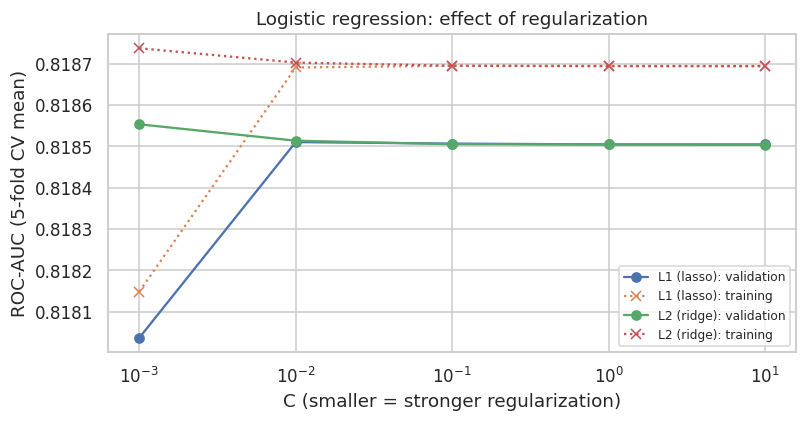

,penalty,C,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc
0,L2 (ridge),0.001,0.8187,0.8186,0.0023
2,L2 (ridge),0.010,0.8187,0.8185,0.0023
3,L1 (lasso),0.010,0.8187,0.8185,0.0023
5,L1 (lasso),0.100,0.8187,0.8185,0.0023
4,L2 (ridge),0.100,0.8187,0.8185,0.0023


In [7]:
# How does regularization strength affect performance? (train vs. validation score shows over/underfitting)
res = pd.DataFrame(lr_search.cv_results_)
res['penalty'] = res['param_model__l1_ratio'].map({0.0: 'L2 (ridge)', 1.0: 'L1 (lasso)'})
res['C'] = res['param_model__C'].astype(float)

fig, ax = plt.subplots(figsize=(7.5, 4))
for pen, g in res.groupby('penalty'):
    g = g.sort_values('C')
    ax.plot(g['C'], g['mean_test_roc_auc'], marker='o', label=f'{pen}: validation')
    ax.plot(g['C'], g['mean_train_roc_auc'], marker='x', ls=':', label=f'{pen}: training')
ax.set(xscale='log', xlabel='C (smaller = stronger regularization)', ylabel='ROC-AUC (5-fold CV mean)',
       title='Logistic regression: effect of regularization')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
res[['penalty', 'C', 'mean_train_roc_auc', 'mean_test_roc_auc', 'std_test_roc_auc']].sort_values('mean_test_roc_auc', ascending=False).head(5).round(4)

**Reading the regularization results:** all ten settings score within 0.0006 ROC-AUC of each other (nine of the ten within 0.0001; only the very strongest L1 shrinkage is slightly lower at 0.8180), and the training score (0.8187) is essentially identical to the validation score (0.8186). That tells us two things: (1) logistic regression is **not overfitting** (it only has 21 weights and ~200,000 rows), and (2) the choice of L1 vs. L2 and of C hardly matters here. The search picked the strongest regularization (C = 0.001, L2) simply because it was marginally best; we keep it because stronger shrinkage is the safer default when scores tie. (The best value sits at the edge of the grid, but the curve is flat, so extending the grid would not change the result.)

## 6. Model 2: Random Forest (ensemble of decision trees)

A random forest averages many decision trees, each trained on a random sample of the data and features. Each tree can capture *interactions* (e.g., "high blood pressure AND older age"), and averaging reduces overfitting. We tune the depth of the trees (deeper = more flexible but risk of overfitting) and the minimum samples per leaf (larger = smoother).

In [8]:
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                            n_jobs=1, random_state=RANDOM_STATE)
rf_grid = {'max_depth': [8, 12, 16],
           'min_samples_leaf': [20, 50]}
rf_search = run_grid('Random Forest', rf, rf_grid)

Random Forest: best CV ROC-AUC = 0.8226 | best params = {'max_depth': 16, 'min_samples_leaf': 20} | 412s


## 7. Model 3: Gradient Boosting (ensemble of sequential trees)

Gradient boosting builds small trees *one after another*, each focusing on the mistakes of the previous ones. It is usually the strongest model for tabular (spreadsheet-style) data, so it is the toughest benchmark for the neural network. We use scikit-learn's `HistGradientBoostingClassifier` (fast on large data) and tune the learning rate, tree depth and number of boosting rounds.

In [9]:
hgb = HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)
hgb_grid = {'learning_rate': [0.05, 0.1],
            'max_depth': [2, 3, 4],
            'max_iter': [200, 400]}
hgb_search = run_grid('Gradient Boosting', hgb, hgb_grid)

Gradient Boosting: best CV ROC-AUC = 0.8250 | best params = {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 400} | 424s


## 8. Comparing Cross-Validated Results

,CV ROC-AUC,ROC-AUC std,CV PR-AUC,CV Recall,CV F1,Train ROC-AUC,Train - CV gap
Model,,,,,,,
Logistic Regression,0.8186,0.0023,0.4381,0.7625,0.4706,0.8187,0.0002
Random Forest,0.8226,0.0016,0.4550,0.7525,0.4755,0.8573,0.0346
Gradient Boosting,0.8250,0.0020,0.4584,0.7896,0.4701,0.8285,0.0035


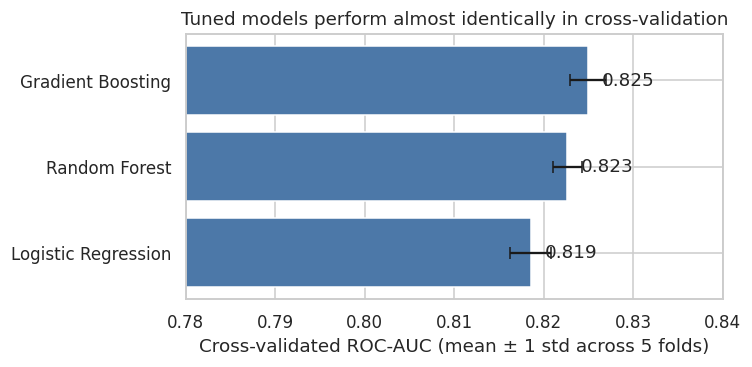

In [10]:
searches = {'Logistic Regression': lr_search, 'Random Forest': rf_search, 'Gradient Boosting': hgb_search}
rows = []
for name, gs in searches.items():
    i = gs.best_index_
    r = gs.cv_results_
    rows.append({'Model': name,
                 'CV ROC-AUC': r['mean_test_roc_auc'][i], 'ROC-AUC std': r['std_test_roc_auc'][i],
                 'CV PR-AUC': r['mean_test_pr_auc'][i],
                 'CV Recall': r['mean_test_recall'][i], 'CV F1': r['mean_test_f1'][i],
                 'Train ROC-AUC': r['mean_train_roc_auc'][i]})
cv_summary = pd.DataFrame(rows).set_index('Model')
cv_summary['Train - CV gap'] = cv_summary['Train ROC-AUC'] - cv_summary['CV ROC-AUC']
display(cv_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cv_summary.index, cv_summary['CV ROC-AUC'], xerr=cv_summary['ROC-AUC std'], color='#4C78A8', capsize=4)
ax.set(xlim=(0.78, 0.84), xlabel='Cross-validated ROC-AUC (mean ± 1 std across 5 folds)',
       title='Tuned models perform almost identically in cross-validation')
for y_pos, v in enumerate(cv_summary['CV ROC-AUC']):
    ax.text(v + 0.0015, y_pos, f'{v:.3f}', va='center')
plt.tight_layout(); plt.show()

**Reading the cross-validation results**

- **Gradient boosting is best (0.825), then random forest (0.823), then logistic regression (0.819).** The largest gap (about 0.006, logistic regression to gradient boosting) is only about 3 times the fold-to-fold variation (±0.002), so the models are close.
- **Overfitting check (train vs. cross-validation gap):** logistic regression 0.0002 (none), gradient boosting 0.0035 (negligible), **random forest 0.035 (mild overfitting)**: it fits the training data noticeably better than the validation folds, even with limited tree depth.
- We widened the gradient-boosting search after a first run placed its best settings at the edge of the grid; the wider search improved the CV score by only 0.0001 (0.8249 → 0.8250), so this benchmark is essentially at its ceiling.

## 9. Final Evaluation on the Held-Out Test Set
The test set has not been used for any tuning decisions. This is the first and only time each model sees it.

In [11]:
best_models = {name: gs.best_estimator_ for name, gs in searches.items()}
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in best_models.items()}

test_table = pd.DataFrame([dummy_row] + [evaluate(n, y_test, p) for n, p in test_proba.items()]).set_index('Model')
display(test_table.round(3))

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
"Always predict ""not at risk""",0.500,0.158,0.000,0.000,0.000,0.842
Logistic Regression,0.818,0.442,0.761,0.342,0.471,0.731
Random Forest,0.822,0.458,0.751,0.347,0.474,0.738
Gradient Boosting,0.825,0.462,0.784,0.336,0.470,0.721


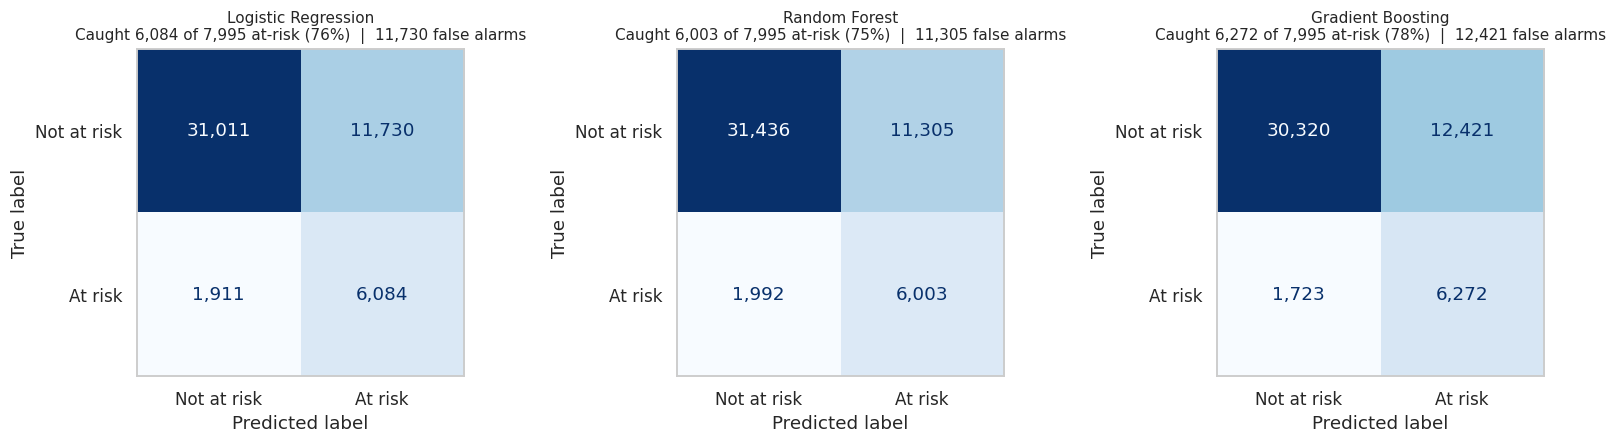

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, p) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['Not at risk', 'At risk']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',d')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{name}\nCaught {tp:,} of {tp+fn:,} at-risk ({tp/(tp+fn):.0%})  |  {fp:,} false alarms', fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.savefig(IMG + 'confusion_matrices_classical.png', bbox_inches='tight'); plt.show()

### Reading the test-set results

- **All three models are far better than the do-nothing baseline:** ROC-AUC 0.818-0.825 (vs. 0.5), PR-AUC 0.44-0.46 (vs. 0.16, the at-risk share) and recall 75-78% (vs. 0%).
- **Test scores match cross-validation scores,** so the models are not over-tuned to the training data.
- **Accuracy is *lower* (72-74%) than the 84% of the do-nothing model.** This is expected and acceptable: to catch about 3 in 4 at-risk people the models must flag many more people than are truly at risk. Accuracy rewards ignoring the minority, which is the opposite of what screening needs.
- **Error trade-offs at the 0.5 cut-off** (7,995 truly at-risk people in the test set):
  - Gradient boosting catches the most (6,272 of 7,995, i.e. 78%) but has the most false alarms (12,421).
  - Logistic regression catches 6,084 (76%) with 11,730 false alarms.
  - Random forest catches 6,003 (75%) with 11,305 false alarms, giving it the best precision (35%).
- **Precision is only about 34%:** roughly 2 of every 3 people flagged are *not* at risk according to the survey label. That is the price of catching three quarters of true cases from survey answers alone (no lab values).
- **Differences between the models are small** (about 0.007 ROC-AUC from worst to best). Notebook 3 tests whether a neural network can do meaningfully better.

## 10. Sensitivity Check: Does Removing Duplicate Rows Change the Conclusions?
In Notebook 1 we kept duplicate rows because they are different respondents with identical answers. To confirm this choice is not driving our results, we repeat the experiment on the de-duplicated data (new stratified split, same tuned hyperparameters) and compare.

In [13]:
df_dedup = df.drop_duplicates()
Xd, yd = df_dedup.drop(columns=['Diabetes_012', 'at_risk']), df_dedup['at_risk']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.20, stratify=yd, random_state=RANDOM_STATE)

sens_rows = []
for name, gs in searches.items():
    if name == 'Random Forest':
        continue                                     # keep the check quick: LR and gradient boosting are enough
    m_dedup = clone(gs.best_estimator_).fit(Xd_tr, yd_tr)
    sens_rows.append({'Model': name,
                      'Test ROC-AUC (all rows)': roc_auc_score(y_test, test_proba[name]),
                      'Test ROC-AUC (duplicates removed)': roc_auc_score(yd_te, m_dedup.predict_proba(Xd_te)[:, 1])})
sens = pd.DataFrame(sens_rows).set_index('Model')
sens['Difference'] = sens.iloc[:, 1] - sens.iloc[:, 0]
print(f'Rows with duplicates: {len(df):,}  |  without duplicates: {len(df_dedup):,}')
sens.round(4)

Rows with duplicates: 253,680  |  without duplicates: 229,772


,Test ROC-AUC (all rows),Test ROC-AUC (duplicates removed),Difference
Model,,,
Logistic Regression,0.8184,0.8019,-0.0165
Gradient Boosting,0.8246,0.8099,-0.0147


**Interpretation:** without duplicates, absolute test ROC-AUC is about 0.015-0.017 lower (logistic regression 0.818 → 0.802; gradient boosting 0.825 → 0.810). This is expected: the removed rows are mostly very common *healthy* answer patterns, which are easy to classify, so the remaining people are harder on average. Importantly, **the model ranking and the gap between models are essentially unchanged** (gradient boosting beats logistic regression by 0.006 with duplicates and 0.008 without). Keeping the duplicates therefore does not change our conclusions, and it keeps the sample faithful to the real population, where those common profiles really are frequent.

## 11. Save Results for Notebook 3

In [14]:
# Test-set probabilities (so Notebook 3 can compare all four models on identical rows)
out = pd.DataFrame(test_proba, index=X_test.index)
out.insert(0, 'y_true', y_test)
out.to_csv(RES + 'classical_test_probabilities.csv')

# Best hyperparameters and CV scores
params = {name: {k: (float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer,)) else v)
                 for k, v in gs.best_params_.items()} for name, gs in searches.items()}
with open(RES + 'classical_best_params.json', 'w') as f:
    json.dump(params, f, indent=2)
cv_summary.round(4).to_csv(RES + 'classical_cv_summary.csv')
print(json.dumps(params, indent=2))

{
  "Logistic Regression": {
    "model__C": 0.001,
    "model__l1_ratio": 0.0
  },
  "Random Forest": {
    "max_depth": 16,
    "min_samples_leaf": 20
  },
  "Gradient Boosting": {
    "learning_rate": 0.05,
    "max_depth": 3,
    "max_iter": 400
  }
}


## 12. Summary and Next Steps

| Model | Tuned settings (best of grid) | CV ROC-AUC | Test ROC-AUC | Test recall | Test precision |
|---|---|---|---|---|---|
| Logistic regression | L2 penalty, C = 0.001 | 0.819 | 0.818 | 76% | 34% |
| Random forest | max depth 16, min leaf 20 | 0.823 | 0.822 | 75% | 35% |
| Gradient boosting | learning rate 0.05, depth 3, 400 rounds | 0.825 | 0.825 | 78% | 34% |

- **Gradient boosting is the strongest classical model, but all three are within 0.007 ROC-AUC.** The survey features carry a limited amount of signal and even flexible models cannot extract much more than a simple one.
- Logistic regression is not overfitting and the forest only mildly so; the tuned models generalize well to unseen test people.
- Duplicate rows do not affect the conclusions.

**Next:** Notebook 3 trains a deep neural network and tests whether it can beat these benchmarks, then turns the best model into screening guidance.